In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Day 17: EconoCausal Results Visualization")
print("Libraries imported successfully!")


Day 17: EconoCausal Results Visualization
Libraries imported successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving Online Retail.xlsx to Online Retail.xlsx


In [3]:

import pandas as pd

df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (541909, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:

# Create a copy of the dataset
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Convert columns to the correct data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)

# Keep valid dates and positive price and quantity
df_clean = df_clean.dropna(
    subset=["InvoiceDate", "UnitPrice", "Quantity"]
)
df_clean = df_clean[
    (df_clean["UnitPrice"] > 0) &
    (df_clean["Quantity"] > 0)
].copy()

# Create a monthly feature
df_clean["Month"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

# Generate monthly summary
monthly_summary = (
    df_clean.groupby("Month")
    .agg(
        MeanUnitPrice=("UnitPrice", "mean"),
        MedianQuantity=("Quantity", "median"),
        TransactionRows=("Quantity", "size")
    )
    .reset_index()
)

print("Data cleaning completed!")
print("Cleaned dataset shape:", df_clean.shape)
display(monthly_summary.head(10))


Data cleaning completed!
Cleaned dataset shape: (524878, 9)


,Month,MeanUnitPrice,MedianQuantity,TransactionRows
0,2010-12,4.846114,2.0,40991
1,2011-01,3.787057,3.0,34060
2,2011-02,4.002696,3.0,26882
3,2011-03,4.082854,4.0,35497
4,2011-04,3.986188,4.0,28882
5,2011-05,4.170440,4.0,35917
6,2011-06,3.907644,4.0,35716
7,2011-07,3.712157,3.0,38395
8,2011-08,4.024723,4.0,34264
9,2011-09,3.555724,4.0,48900


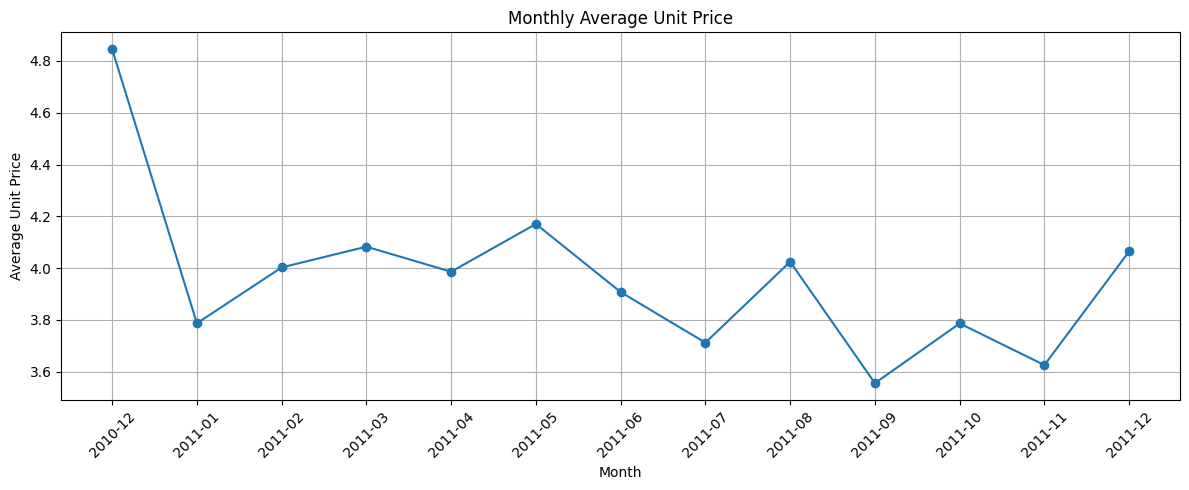

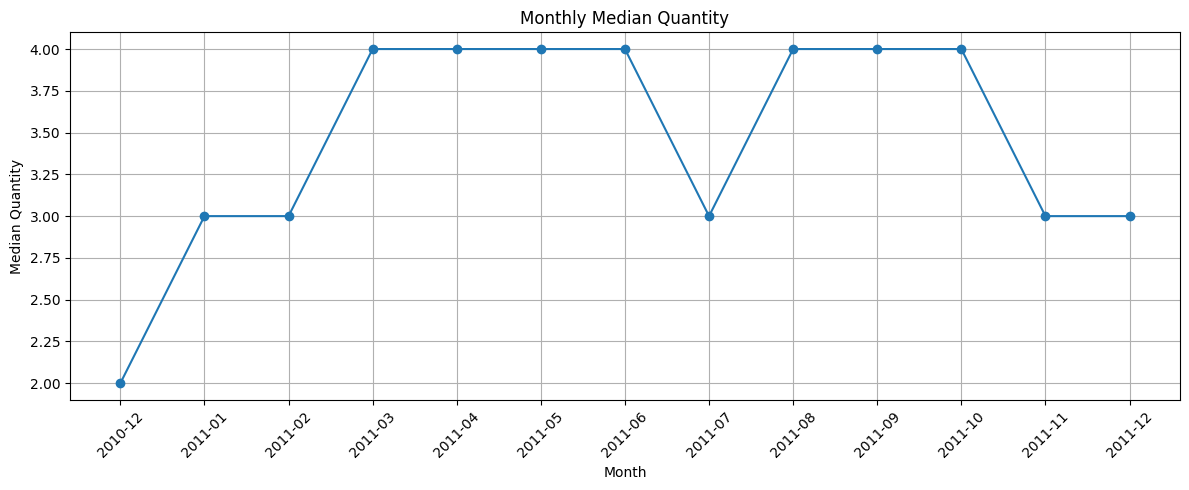

In [5]:

# Graph 1: Monthly Average Unit Price
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Month"],
    monthly_summary["MeanUnitPrice"],
    marker="o"
)
plt.title("Monthly Average Unit Price")
plt.xlabel("Month")
plt.ylabel("Average Unit Price")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Graph 2: Monthly Median Quantity
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_summary["Month"],
    monthly_summary["MedianQuantity"],
    marker="o"
)
plt.title("Monthly Median Quantity")
plt.xlabel("Month")
plt.ylabel("Median Quantity")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:

monthly_summary.to_csv(
    "day17_monthly_price_quantity_summary.csv",
    index=False
)

print("Day 17 monthly summary saved successfully!")


Day 17 monthly summary saved successfully!


In [7]:

from google.colab import files

files.download("day17_monthly_price_quantity_summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>